# Практическое занятие 05. Обучение линейной регрессии: МНК и градиентный спуск

Цель занятия: реализовать метод наименьших квадратов и градиентный спуск на NumPy, сверить их с `LinearRegression` и `SGDRegressor` и увидеть, как скорость обучения, масштаб признаков и размер пакета влияют на сходимость.

Основа — лекция 04 и глава 4 книги Орельена Жерона «Прикладное машинное обучение с помощью Scikit-Learn и TensorFlow», стр. 153–172, а также блокнот Данила Зитцера «Градиентный спуск шаг за шагом» (Deep Learning Notes 02). Теорию разбирали на лекции, здесь — код.

План:

- три точки и прямая: остатки, сумма квадратов, поверхность функции потерь — 12 мин;
- линейная регрессия в векторной форме и нормальное уравнение — 8 мин;
- вычислительная сложность — 4 мин;
- градиентный спуск: шаги вручную, траектория, скорость обучения, остановка — 16 мин;
- масштаб признаков — 5 мин;
- стохастический и мини-пакетный спуск, `SGDRegressor`, сравнение алгоритмов — 12 мин;
- задание: прогноз пульса бегуна — 15 мин.

In [1]:
import sys

import matplotlib
import numpy as np
import pandas as pd
import sklearn

sys.version, np.__version__, pd.__version__, matplotlib.__version__, sklearn.__version__

('3.8.10 (default, Jun 22 2022, 20:18:18) \n[GCC 9.4.0]',
 '1.24.4',
 '2.0.3',
 '3.7.5',
 '1.3.2')

In [2]:
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (7, 4.5)

# Три точки и прямая

Источники: [Deep Learning Notes 02](https://github.com/DanilZittser/deep-learning-notes/blob/ec1bce0f16a9884ce54222a7918e35a10c754f1d/02_gradient_descent_step_by_step/src/01_gradient_descent_step_by_step.ipynb), раздел «Постановка задачи»; книга, гл. 4, стр. 154–156.

На плоскости три точки: (0, 0), (1, 1), (2, 1). Нужно провести прямую $\hat{y} = a x + b$ как можно ближе ко всем трём сразу. Это задача регрессии в миниатюре: один признак $x$, целевой признак $y$ и два параметра — наклон $a$ и сдвиг $b$.

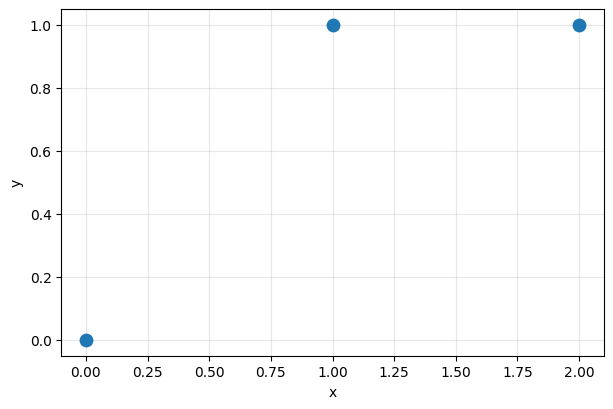

In [3]:
x_points = np.array([0.0, 1.0, 2.0])
y_points = np.array([0.0, 1.0, 1.0])

plt.scatter(x_points, y_points, s=80, zorder=3)
plt.xlabel('x')
plt.ylabel('y')
plt.grid(alpha=0.3)
plt.show()

Прямых «между точками» бесконечно много. Нарисуем три кандидата — какая лучше, на глаз сказать трудно:

In [4]:
def predict_line(x, slope, intercept):
    """Вычисляет прогноз прямой y = slope * x + intercept.

    Args:
        x: Значения признака.
        slope: Наклон прямой.
        intercept: Сдвиг прямой.

    Returns:
        Прогнозы прямой в точках x.
    """
    return slope * x + intercept

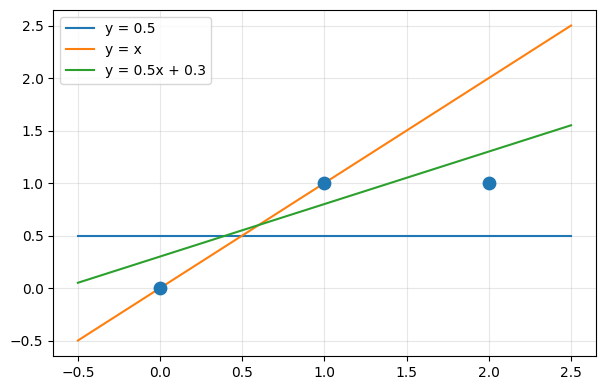

In [5]:
candidates = {'y = 0.5': (0.0, 0.5), 'y = x': (1.0, 0.0), 'y = 0.5x + 0.3': (0.5, 0.3)}
x_grid = np.linspace(-0.5, 2.5, 50)

plt.scatter(x_points, y_points, s=80, zorder=3)
for label, (slope, intercept) in candidates.items():
    plt.plot(x_grid, predict_line(x_grid, slope, intercept), label=label)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Остатки

Остаток (англ. *residual*) $e_i = y_i - \hat{y}_i$ — промах прямой на одной точке по вертикали. Для горизонтальной прямой $y = 0{,}5$:

In [6]:
residuals = y_points - predict_line(x_points, 0.0, 0.5)
residuals, residuals.sum()

(array([-0.5,  0.5,  0.5]), 0.5)

**Как неправильно.** Сумма остатков — плохая мера: положительные и отрицательные промахи гасят друг друга. Горизонтальная прямая на уровне среднего $y$ даёт нулевую сумму, хотя не проходит ни через одну точку:

In [7]:
residuals_mean_line = y_points - predict_line(x_points, 0.0, y_points.mean())
residuals_mean_line, round(residuals_mean_line.sum(), 12)

(array([-0.66666667,  0.33333333,  0.33333333]), 0.0)

**Как правильно.** Возводим остатки в квадрат: знак пропадает, большие промахи штрафуются сильнее. Сумма квадратов $S(a, b) = \sum_i (y_i - a x_i - b)^2$ зависит только от параметров прямой — точки фиксированы:

In [8]:
def sum_of_squares(slope, intercept):
    """Вычисляет сумму квадратов остатков прямой на трёх точках.

    Args:
        slope: Наклон прямой.
        intercept: Сдвиг прямой.

    Returns:
        Сумма квадратов остатков.
    """
    return np.sum((y_points - predict_line(x_points, slope, intercept)) ** 2)

In [9]:
for label, (slope, intercept) in candidates.items():
    print(f'{label:>16}: S = {sum_of_squares(slope, intercept):.3f}')

         y = 0.5: S = 0.750
           y = x: S = 1.000
  y = 0.5x + 0.3: S = 0.220


Если подставить координаты точек и раскрыть скобки, получится многочлен из лекции: $S(a, b) = 5a^2 + 3b^2 + 6ab - 6a - 4b + 2$. Проверим в точке $a = b = 1$:

In [10]:
slope, intercept = 1.0, 1.0
sum_of_squares(slope, intercept), 5 * slope**2 + 3 * intercept**2 + 6 * slope * intercept - 6 * slope - 4 * intercept + 2

(6.0, 6.0)

## Поверхность функции потерь

Посчитаем $S$ на сетке параметров. Транслирование NumPy делает это без циклов: к сетке формы (200, 200) добавляем ось точек и суммируем по ней.

In [11]:
slope_grid, intercept_grid = np.meshgrid(np.linspace(-1, 2, 200), np.linspace(-1.5, 1.5, 200))
predictions_grid = slope_grid[..., np.newaxis] * x_points + intercept_grid[..., np.newaxis]
loss_grid = ((y_points - predictions_grid) ** 2).sum(axis=-1)
predictions_grid.shape, loss_grid.shape

((200, 200, 3), (200, 200))

In [12]:
def plot_loss_contours(ax):
    """Рисует линии уровня функции S(a, b) и её минимум.

    Args:
        ax: Оси matplotlib.
    """
    contours = ax.contourf(slope_grid, intercept_grid, loss_grid, levels=np.geomspace(0.17, 20, 25), cmap='viridis')
    ax.contour(slope_grid, intercept_grid, loss_grid, levels=np.geomspace(0.17, 20, 12), colors='white', linewidths=0.5)
    ax.plot(0.5, 1 / 6, 'r*', markersize=14, label='минимум')
    ax.set_xlabel('наклон a')
    ax.set_ylabel('сдвиг b')
    return contours

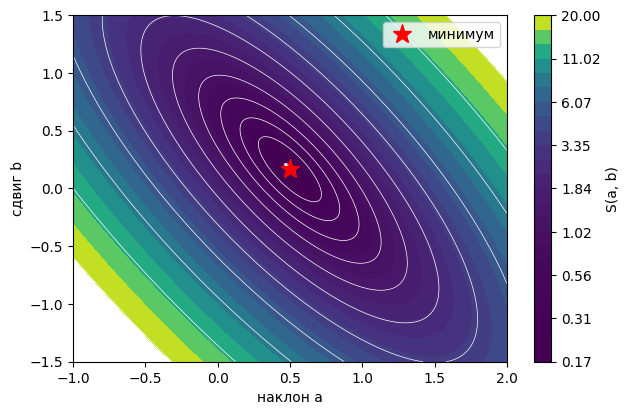

In [13]:
fig, ax = plt.subplots()
contours = plot_loss_contours(ax)
fig.colorbar(contours, label='S(a, b)')
ax.legend()
plt.show()

Поверхность — вытянутая чаша с единственным дном. На лекции мы нашли его, приравняв частные производные к нулю: $\partial S / \partial a = 10a + 6b - 6 = 0$, $\partial S / \partial b = 6a + 6b - 4 = 0$. Это линейная система, NumPy решает её одной строкой:

In [14]:
best_slope, best_intercept = np.linalg.solve([[10, 6], [6, 6]], [6, 4])
best_slope, best_intercept, sum_of_squares(best_slope, best_intercept)

(0.5000000000000001, 0.1666666666666665, 0.16666666666666663)

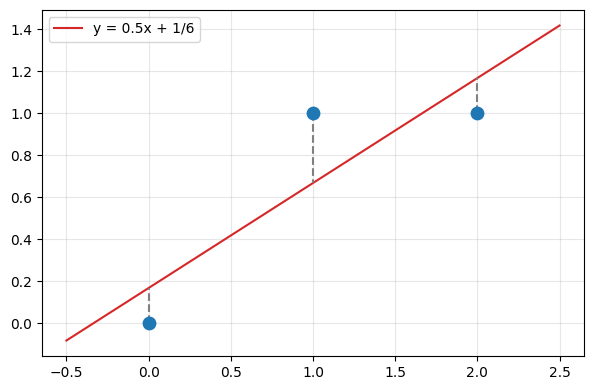

In [15]:
plt.scatter(x_points, y_points, s=80, zorder=3)
plt.plot(x_grid, predict_line(x_grid, best_slope, best_intercept), color='tab:red', label='y = 0.5x + 1/6')
plt.vlines(x_points, y_points, predict_line(x_points, best_slope, best_intercept), colors='gray', linestyles='--')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Серые отрезки — остатки лучшей прямой; меньшей суммы их квадратов, чем $1/6$, не даст ни одна прямая. Это и есть метод наименьших квадратов (англ. *least squares*).

# Линейная регрессия и нормальное уравнение

Книга: гл. 4, стр. 154–159.

Линейная модель прогнозирует взвешенную сумму признаков плюс свободный член. Если добавить к каждому образцу фиктивный признак $x_0 = 1$, прогноз записывается скалярным произведением $\hat{y} = \theta^T \mathbf{x}$ (уравнение 4.2), а для всего набора — матричным $\hat{\mathbf{y}} = X\theta$.

Данные — как в книге: $y = 4 + 3x_1 + \text{гауссов шум}$, 100 образцов.

In [16]:
rng = np.random.default_rng(42)
m = 100
X = 2 * rng.random((m, 1))
y = 4 + 3 * X[:, 0] + rng.standard_normal(m)
X.shape, y.shape

((100, 1), (100,))

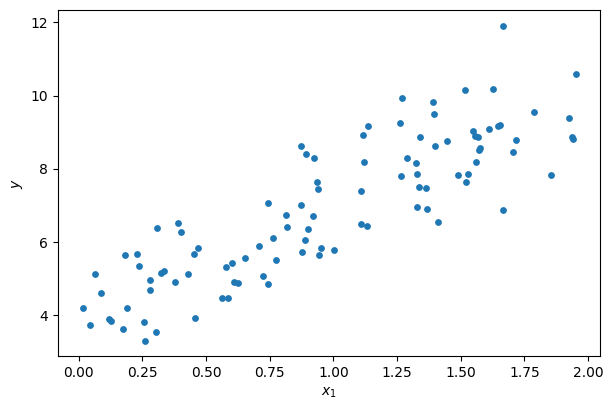

In [17]:
plt.scatter(X, y, s=15)
plt.xlabel('$x_1$')
plt.ylabel('$y$')
plt.show()

Добавляем столбец единиц — это $x_0$ для свободного члена $\theta_0$:

In [18]:
X_b = np.c_[np.ones(m), X]
X_b[:3]

array([[1.        , 1.5479121 ],
       [1.        , 0.87775688],
       [1.        , 1.71719584]])

Функция издержек — среднеквадратичная ошибка (англ. *mean squared error*, *MSE*), уравнение 4.3: $\text{MSE}(\theta) = \frac{1}{m}\sum_i (\theta^T \mathbf{x}^{(i)} - y^{(i)})^2$. В матричном виде — одна строка:

In [19]:
def mse(theta, features, target):
    """Вычисляет MSE линейной модели с параметрами theta.

    Args:
        theta: Вектор параметров, первый элемент — свободный член.
        features: Матрица признаков со столбцом единиц.
        target: Вектор целевых значений.

    Returns:
        Среднеквадратичная ошибка.
    """
    return np.mean((features @ theta - target) ** 2)

In [20]:
mse(np.array([4.0, 3.0]), X_b, y), mse(np.zeros(2), X_b, y)

(0.9594953110260015, 51.39282423721241)

Истинные параметры дают MSE около 1 — это дисперсия шума, лучше в среднем не сделать.

Нормальное уравнение (англ. *normal equation*, уравнение 4.4) сразу даёт параметры с наименьшей MSE:

$$\hat{\theta} = (X^T X)^{-1} X^T \mathbf{y}$$

Писать его руками на практике не нужно — это делает scikit-learn.

## [`LinearRegression`](https://scikit-learn.org/1.3/modules/generated/sklearn.linear_model.LinearRegression.html)

`LinearRegression` сама добавляет свободный член и хранит его отдельно от весов признаков: `intercept_` и `coef_` (стр. 158). Столбец единиц ей не нужен — передаём исходный `X`.

In [21]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)
lin_reg.intercept_, lin_reg.coef_

(3.9486997265503043, array([3.03831479]))

Близко к истинным 4 и 3, но не точно: шум не позволяет восстановить параметры по 100 точкам. Сверим с формулой и с `np.linalg.lstsq` — функцией NumPy для задачи наименьших квадратов; на ней же основана `LinearRegression`, которая не обращает $X^T X$, а решает задачу через сингулярное разложение — так устойчивее.

In [22]:
theta_normal = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
theta_lstsq = np.linalg.lstsq(X_b, y, rcond=None)[0]
theta_normal, theta_lstsq

(array([3.94869973, 3.03831479]), array([3.94869973, 3.03831479]))

Прогноз для новых $x_1 = 0$ и $x_1 = 2$ и прямая модели:

In [23]:
X_new = np.array([[0.0], [2.0]])
y_new = lin_reg.predict(X_new)
y_new

array([ 3.94869973, 10.02532931])

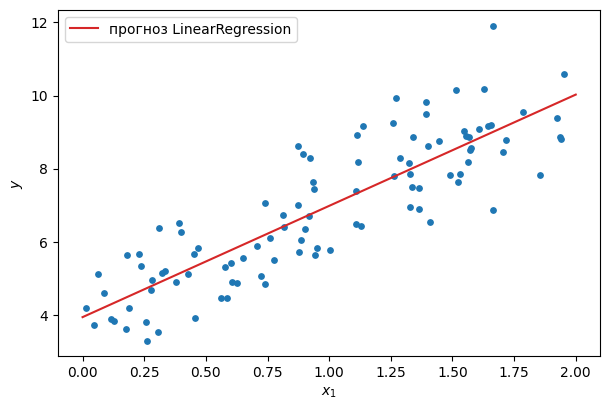

In [24]:
plt.scatter(X, y, s=15)
plt.plot(X_new, y_new, color='tab:red', label='прогноз LinearRegression')
plt.xlabel('$x_1$')
plt.ylabel('$y$')
plt.legend()
plt.show()

# Вычислительная сложность

Книга: гл. 4, стр. 159–160.

Нормальное уравнение обращает матрицу $X^T X$ размера $n \times n$, где $n$ — число признаков; это стоит от $O(n^{2,4})$ до $O(n^3)$. Проверим замером: удвоение $n$ должно увеличивать время в несколько раз. Функция берёт лучшее из трёх запусков, чтобы фоновые процессы не портили замер.

In [25]:
from time import perf_counter


def best_time(function, repeats=3):
    """Измеряет лучшее время выполнения функции без аргументов.

    Args:
        function: Измеряемая функция.
        repeats: Число запусков.

    Returns:
        Лучшее время в секундах.
    """
    times = []
    for _ in range(repeats):
        start = perf_counter()
        function()
        times.append(perf_counter() - start)
    return min(times)

In [26]:
inverse_times = {}
for n_features in (400, 800, 1600):
    features = rng.standard_normal((2 * n_features, n_features))
    gram = features.T @ features
    inverse_times[n_features] = best_time(lambda: np.linalg.inv(gram))

inverse_times = pd.Series(inverse_times, name='секунды')
pd.DataFrame({'секунды': inverse_times, 'рост': inverse_times / inverse_times.shift()}).round(4)

,секунды,рост
400,0.0026,NaN
800,0.0141,5.3238
1600,0.1037,7.3743


Рост при удвоении — в несколько раз; точный множитель зависит от процессора и библиотеки линейной алгебры. По числу образцов $m$ время растёт линейно: от $m$ зависит только сборка $X^T X$ и $X^T \mathbf{y}$, а решается система $n \times n$. Проверим на нормальном уравнении с 50 признаками:

In [27]:
fit_times = {}
for n_samples in (100_000, 200_000, 400_000):
    features = rng.standard_normal((n_samples, 50))
    target = rng.standard_normal(n_samples)
    fit_times[n_samples] = best_time(lambda: np.linalg.solve(features.T @ features, features.T @ target))

fit_times = pd.Series(fit_times)
pd.DataFrame({'секунды': fit_times, 'рост': fit_times / fit_times.shift()}).round(4)

,секунды,рост
100000,0.0124,NaN
200000,0.0247,1.9977
400000,0.0485,1.9620


Вывод: при сотнях тысяч признаков или наборе, который не помещается в память, нормальное уравнение не годится — нужен итеративный способ, градиентный спуск.

# Градиентный спуск

Источники: книга, гл. 4, стр. 160–167; [Deep Learning Notes 02](https://github.com/DanilZittser/deep-learning-notes/blob/ec1bce0f16a9884ce54222a7918e35a10c754f1d/02_gradient_descent_step_by_step/src/01_gradient_descent_step_by_step.ipynb), разделы «Введение в градиентный спуск» и «Шаги ГС».

Градиентный спуск (англ. *gradient descent*) начинает со случайных параметров и маленькими шагами идёт против градиента функции издержек, пока не дойдёт до минимума.

![Шаги градиентного спуска на трёх точках](https://raw.githubusercontent.com/DanilZittser/deep-learning-notes/ec1bce0f16a9884ce54222a7918e35a10c754f1d/02_gradient_descent_step_by_step/gifs/01.gif)

## Производная и касательная

Вблизи точки $x_0$ гладкая функция почти совпадает со своей касательной: $f(x) \approx f(x_0) + f'(x_0)(x - x_0)$. Для $f(x) = x^2$ в $x_0 = 2$ это $4x - 4$: функция растёт с ростом $x$, значит, для уменьшения $x$ надо уменьшать.

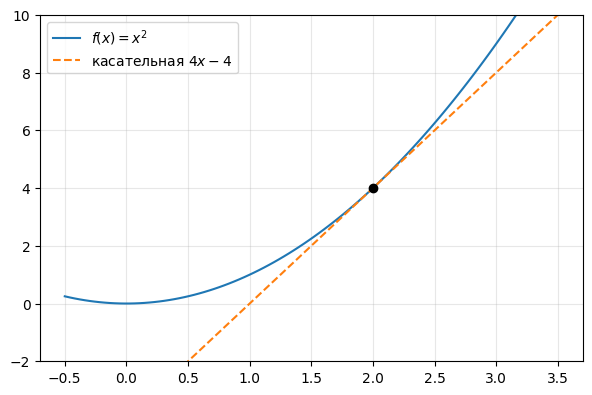

In [28]:
x_parabola = np.linspace(-0.5, 3.5, 100)

plt.plot(x_parabola, x_parabola**2, label='$f(x) = x^2$')
plt.plot(x_parabola, 4 * x_parabola - 4, '--', label='касательная $4x - 4$')
plt.plot(2, 4, 'ko')
plt.ylim(-2, 10)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Правило шага $x_{\text{след}} = x - \alpha f'(x)$: шагаем против производной; множитель $\alpha$ — скорость обучения (англ. *learning rate*). У минимума производная мала, и шаги укорачиваются сами:

In [29]:
x_current = 2.0
for step in range(1, 6):
    x_current = x_current - 0.1 * 2 * x_current
    print(f'шаг {step}: x = {x_current:.4f}, f(x) = {x_current**2:.4f}')

шаг 1: x = 1.6000, f(x) = 2.5600
шаг 2: x = 1.2800, f(x) = 1.6384
шаг 3: x = 1.0240, f(x) = 1.0486
шаг 4: x = 0.8192, f(x) = 0.6711
шаг 5: x = 0.6554, f(x) = 0.4295


## Три шага вручную на $S(a, b)$

Для нескольких параметров производная заменяется градиентом — вектором частных производных: $\nabla S = (10a + 6b - 6,\ 6a + 6b - 4)$. Шаг: $(a, b)_{\text{след}} = (a, b) - \alpha \nabla S(a, b)$, обе производные считаются в одной и той же текущей точке.

In [30]:
def gradient_sum_of_squares(params):
    """Вычисляет градиент S(a, b) для трёх точек.

    Args:
        params: Массив [наклон, сдвиг].

    Returns:
        Массив частных производных [dS/da, dS/db].
    """
    slope, intercept = params
    return np.array([10 * slope + 6 * intercept - 6, 6 * slope + 6 * intercept - 4])

In [31]:
params = np.array([1.0, 1.0])
learning_rate = 0.1
params, sum_of_squares(*params), gradient_sum_of_squares(params)

(array([1., 1.]), 6.0, array([10.,  8.]))

Шаг 1 — сверьте с лекцией: $a = 0$, $b = 0{,}2$, $S = 1{,}32$:

In [32]:
params = params - learning_rate * gradient_sum_of_squares(params)
params, sum_of_squares(*params)

(array([0. , 0.2]), 1.3200000000000003)

Ещё два шага — $S$ падает до 0,426 и 0,245:

In [33]:
for step in (2, 3):
    params = params - learning_rate * gradient_sum_of_squares(params)
    print(f'шаг {step}: a = {params[0]:.3f}, b = {params[1]:.3f}, S = {sum_of_squares(*params):.3f}')

шаг 2: a = 0.480, b = 0.480, S = 0.426
шаг 3: a = 0.312, b = 0.304, S = 0.245


## Цикл и траектория

Соберём шаги в функцию, которая возвращает всю историю параметров:

In [34]:
def descend_three_points(start, learning_rate, n_steps):
    """Выполняет градиентный спуск по S(a, b) и запоминает путь.

    Args:
        start: Начальные параметры [наклон, сдвиг].
        learning_rate: Скорость обучения.
        n_steps: Число шагов.

    Returns:
        Массив формы (n_steps + 1, 2) с параметрами после каждого шага.
    """
    path = [np.asarray(start, dtype=float)]
    for _ in range(n_steps):
        path.append(path[-1] - learning_rate * gradient_sum_of_squares(path[-1]))
    return np.array(path)

In [35]:
path_three_points = descend_three_points([1.0, 1.0], learning_rate=0.1, n_steps=40)
path_three_points[-1], sum_of_squares(*path_three_points[-1]), np.linalg.norm(gradient_sum_of_squares(path_three_points[-1]))

(array([0.49985366, 0.1668697 ]), 0.16666671913798128, 0.00041931559705962984)

За 40 шагов спуск пришёл к тому же $(0{,}5;\ 1/6)$, что и формула, а градиент почти нулевой. Ошибка падает круто в начале и почти не меняется у дна чаши:

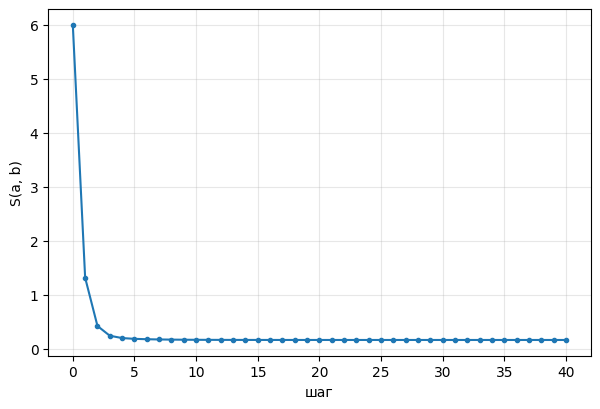

In [36]:
losses_three_points = [sum_of_squares(*params) for params in path_three_points]

plt.plot(losses_three_points, marker='o', markersize=3)
plt.xlabel('шаг')
plt.ylabel('S(a, b)')
plt.grid(alpha=0.3)
plt.show()

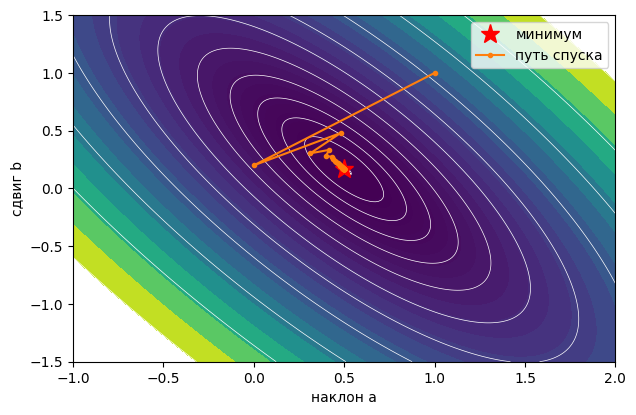

In [37]:
fig, ax = plt.subplots()
plot_loss_contours(ax)
ax.plot(path_three_points[:, 0], path_three_points[:, 1], 'o-', color='tab:orange', markersize=3, label='путь спуска')
ax.legend()
plt.show()

Первые шаги длинные и перескакивают дно долины, затем путь сворачивает к минимуму. Так же поворачивается прямая:

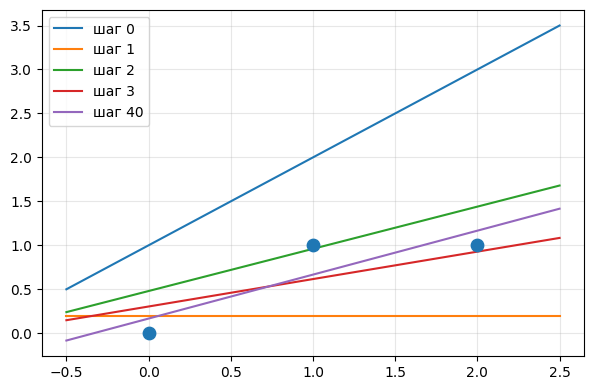

In [38]:
plt.scatter(x_points, y_points, s=80, zorder=3)
for step in (0, 1, 2, 3, 40):
    slope, intercept = path_three_points[step]
    plt.plot(x_grid, predict_line(x_grid, slope, intercept), label=f'шаг {step}')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Скорость обучения

Книга, стр. 160–161 и 165–166. Слишком маленькая скорость обучения требует очень многих шагов, слишком большая — перескакивает долину всё дальше, и спуск расходится. Для $S(a, b)$ граница — около 0,14:

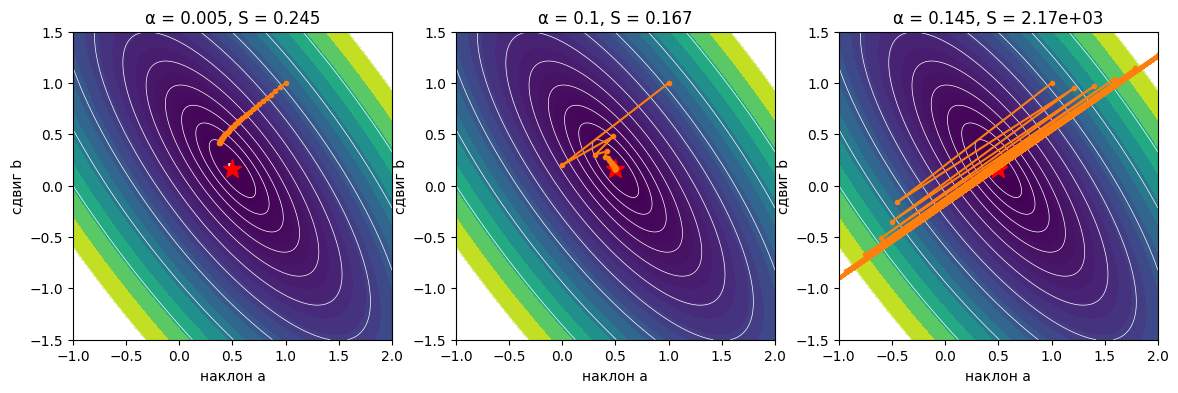

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, rate in zip(axes, (0.005, 0.1, 0.145)):
    path = descend_three_points([1.0, 1.0], learning_rate=rate, n_steps=40)
    plot_loss_contours(ax)
    ax.plot(path[:, 0], path[:, 1], 'o-', color='tab:orange', markersize=3)
    ax.set_xlim(-1, 2)
    ax.set_ylim(-1.5, 1.5)
    ax.set_title(f'α = {rate}, S = {sum_of_squares(*path[-1]):.3g}')
plt.show()

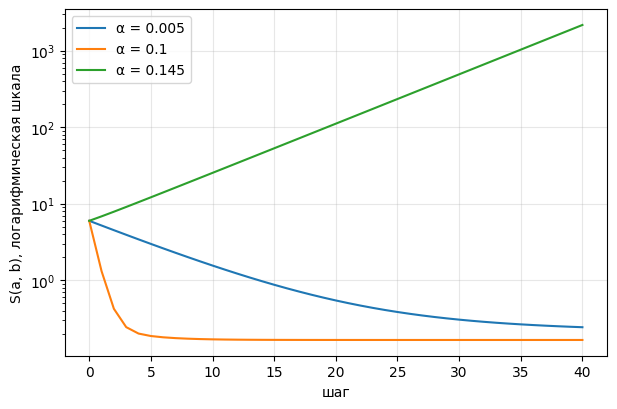

In [40]:
for rate in (0.005, 0.1, 0.145):
    path = descend_three_points([1.0, 1.0], learning_rate=rate, n_steps=40)
    plt.semilogy([sum_of_squares(*params) for params in path], label=f'α = {rate}')
plt.xlabel('шаг')
plt.ylabel('S(a, b), логарифмическая шкала')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Пакетный градиентный спуск в векторной форме

Вернёмся к данным книги. Градиент MSE по всем параметрам сразу (уравнение 4.6): $\nabla_\theta \text{MSE}(\theta) = \frac{2}{m} X^T (X\theta - \mathbf{y})$; шаг — $\theta_{\text{след}} = \theta - \eta \nabla_\theta \text{MSE}(\theta)$ (уравнение 4.7, в книге скорость обучения — $\eta$). В каждом шаге участвует весь обучающий набор, поэтому спуск называется пакетным (англ. *batch gradient descent*).

In [41]:
eta = 0.1
n_iterations = 1000
theta = rng.standard_normal(2)  # Случайная инициализация

for _ in range(n_iterations):
    gradients = 2 / m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients

theta, theta_normal

(array([3.94869973, 3.03831479]), array([3.94869973, 3.03831479]))

Ровно то же, что нормальное уравнение. Первые 10 шагов при трёх скоростях обучения — как на рис. 4.8 книги (стр. 166):

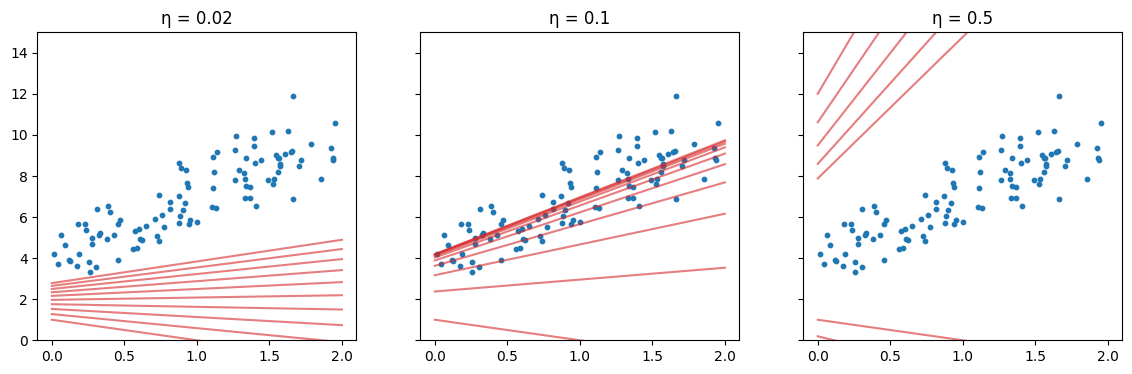

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, rate in zip(axes, (0.02, 0.1, 0.5)):
    theta_demo = np.array([1.0, -1.0])
    ax.scatter(X, y, s=10)
    for _ in range(10):
        ax.plot(X_new, X_new[:, 0] * theta_demo[1] + theta_demo[0], color='tab:red', alpha=0.6)
        theta_demo = theta_demo - rate * 2 / m * X_b.T @ (X_b @ theta_demo - y)
    ax.set_ylim(0, 15)
    ax.set_title(f'η = {rate}')
plt.show()

Слева спуск медленный, посередине сходится за несколько шагов, справа прямая скачет всё сильнее — расходится.

## Когда остановиться

Книга советует ставить большое число итераций и прерывать спуск, когда норма градиента станет меньше допуска $\varepsilon$ (англ. *tolerance*), стр. 166:

In [43]:
def gradient_descent_with_tolerance(features, target, learning_rate, tolerance=1e-6, max_iterations=100_000):
    """Выполняет пакетный градиентный спуск до малой нормы градиента.

    Args:
        features: Матрица признаков со столбцом единиц.
        target: Вектор целевых значений.
        learning_rate: Скорость обучения.
        tolerance: Допуск на норму градиента.
        max_iterations: Наибольшее число итераций.

    Returns:
        Параметры и число выполненных итераций.
    """
    theta = np.zeros(features.shape[1])
    for iteration in range(1, max_iterations + 1):
        gradients = 2 / len(target) * features.T @ (features @ theta - target)
        if np.linalg.norm(gradients) < tolerance:
            break
        theta = theta - learning_rate * gradients
    return theta, iteration

In [44]:
gradient_descent_with_tolerance(X_b, y, learning_rate=0.1)

(array([3.94869714, 3.03831708]), 439)

In [45]:
gradient_descent_with_tolerance(X_b, y, learning_rate=0.01)

(array([3.94869707, 3.03831714]), 4428)

В 10 раз меньшая скорость обучения — примерно в 10 раз больше итераций до того же ответа.

# Масштаб признаков

Книга: гл. 4, стр. 162–163. Документация: [`StandardScaler`](https://scikit-learn.org/1.3/modules/generated/sklearn.preprocessing.StandardScaler.html).

Если признаки различаются по масштабу в сотни раз, чаша функции издержек сильно вытянута: допустимая скорость обучения определяется самым «крупным» признаком, и вдоль «мелкого» спуск ползёт очень долго. Добавим к данным признак в сотни раз крупнее — например, ту же величину в других единицах плюс шум.

In [46]:
X_two_scales = np.c_[X, 300 * rng.random(m)]
y_two_scales = 4 + 3 * X_two_scales[:, 0] + 0.01 * X_two_scales[:, 1] + rng.standard_normal(m)
X_two_scales_b = np.c_[np.ones(m), X_two_scales]
X_two_scales.std(axis=0)

array([ 0.5444962 , 88.24613403])

**Как неправильно.** С прежней скоростью обучения 0,1 спуск сразу расходится — числа переполняются:

In [47]:
with np.errstate(over='ignore', invalid='ignore'):
    theta_unscaled, iterations_unscaled = gradient_descent_with_tolerance(
        X_two_scales_b, y_two_scales, learning_rate=0.1, max_iterations=1000,
    )
theta_unscaled, iterations_unscaled

(array([nan, nan, nan]), 1000)

Скорость, при которой спуск не расходится, приходится уменьшать в тысячи раз — и 100 000 итераций не хватает, чтобы дойти до минимума:

In [48]:
theta_unscaled, iterations_unscaled = gradient_descent_with_tolerance(X_two_scales_b, y_two_scales, learning_rate=2e-5)
theta_two_scales = np.linalg.lstsq(X_two_scales_b, y_two_scales, rcond=None)[0]
theta_unscaled, iterations_unscaled, theta_two_scales

(array([2.88827475, 3.29462688, 0.01461356]),
 100000,
 array([4.62626257, 2.71509058, 0.00895998]))

**Как правильно.** Стандартизируем признаки `StandardScaler` — среднее 0 и стандартное отклонение 1 у каждого. Спуск со скоростью 0,1 сходится за сотню-другую итераций:

In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_two_scales_scaled_b = np.c_[np.ones(m), scaler.fit_transform(X_two_scales)]
theta_scaled, iterations_scaled = gradient_descent_with_tolerance(X_two_scales_scaled_b, y_two_scales, learning_rate=0.1)
theta_scaled, iterations_scaled

(array([8.70027987, 1.4783564 , 0.79068327]), 76)

Параметры другие, потому что модель обучена на стандартизованных признаках; прогнозы же совпадают с решением наименьших квадратов на исходных:

In [50]:
np.allclose(X_two_scales_scaled_b @ theta_scaled, X_two_scales_b @ theta_two_scales, atol=1e-4)

True

Нормальному уравнению и `LinearRegression` масштаб безразличен, градиентному спуску — нет.

# Стохастический и мини-пакетный спуск

Книга: гл. 4, стр. 167–172.

Пакетный спуск на каждом шаге проходит весь набор — на миллионах образцов это медленно. Стохастический градиентный спуск (англ. *stochastic gradient descent*, *SGD*) считает градиент по одному случайному образцу, мини-пакетный (англ. *mini-batch gradient descent*) — по небольшой случайной порции.

## SGD на NumPy

Итерации идут эпохами (англ. *epoch*) по $m$ шагов. Чтобы у минимума путь не скакал бесконечно, скорость обучения постепенно уменьшают по графику скорости обучения (англ. *learning schedule*, в книге — «график обучения») $\eta(t) = t_0 / (t + t_1)$, стр. 168:

In [51]:
def learning_schedule(step, t0=5, t1=50):
    """Вычисляет скорость обучения на шаге step.

    Args:
        step: Номер шага с начала обучения.
        t0: Числитель графика.
        t1: Сдвиг графика.

    Returns:
        Скорость обучения.
    """
    return t0 / (step + t1)

In [52]:
[round(learning_schedule(step), 4) for step in (0, 100, 1000, 4999)]

[0.1, 0.0333, 0.0048, 0.001]

In [53]:
def stochastic_gradient_descent(features, target, n_epochs, seed=42):
    """Выполняет стохастический градиентный спуск и запоминает путь.

    Args:
        features: Матрица признаков со столбцом единиц.
        target: Вектор целевых значений.
        n_epochs: Число эпох.
        seed: Зерно генератора случайных чисел.

    Returns:
        Итоговые параметры и массив параметров после каждого шага.
    """
    generator = np.random.default_rng(seed)
    n_samples = len(target)
    theta = generator.standard_normal(features.shape[1])
    path = [theta]
    for epoch in range(n_epochs):
        for i in range(n_samples):
            index = generator.integers(n_samples)
            gradients = 2 * features[index] * (features[index] @ theta - target[index])
            theta = theta - learning_schedule(epoch * n_samples + i) * gradients
            path.append(theta)
    return theta, np.array(path)

In [54]:
theta_sgd, path_sgd = stochastic_gradient_descent(X_b, y, n_epochs=50)
theta_sgd, path_sgd.shape

(array([3.966486  , 3.04565621]), (5001, 2))

50 эпох по 100 шагов — 5000 дешёвых шагов вместо 1000 шагов по всему набору, и ответ близок к нормальному уравнению. Первые 10 шагов нерегулярны (рис. 4.10, стр. 169):

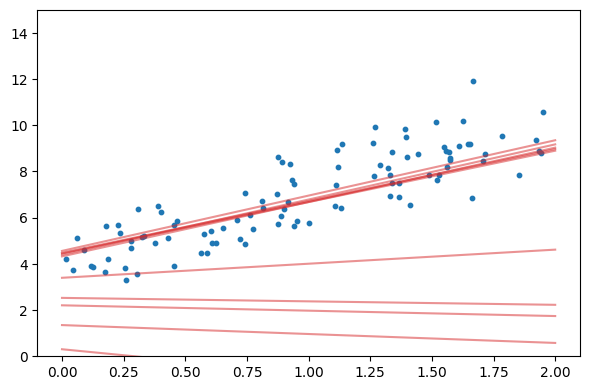

In [55]:
plt.scatter(X, y, s=10)
for theta_step in path_sgd[:10]:
    plt.plot(X_new, X_new[:, 0] * theta_step[1] + theta_step[0], color='tab:red', alpha=0.5)
plt.ylim(0, 15)
plt.show()

## [`SGDRegressor`](https://scikit-learn.org/1.3/modules/generated/sklearn.linear_model.SGDRegressor.html)

В scikit-learn стохастический спуск для линейной регрессии — `SGDRegressor` (стр. 169–170). В книге число эпох задаёт `n_iter`; в версии 1.3 его заменили `max_iter` и `tol` — остановка, когда за эпоху ошибка почти не уменьшилась. `penalty=None` отключает регуляризацию — о ней в практике 06.

In [56]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=1000, tol=1e-3, penalty=None, eta0=0.1, random_state=42)
sgd_reg.fit(X, y)
sgd_reg.intercept_, sgd_reg.coef_, sgd_reg.n_iter_

(array([3.9632239]), array([3.04674798]), 9)

## Мини-пакетный спуск

Каждую эпоху набор перемешивается и режется на мини-пакеты по 20 образцов; градиент — среднее по пакету. Скорость обучения уменьшается по тому же графику с другими $t_0$ и $t_1$:

In [57]:
def mini_batch_gradient_descent(features, target, n_epochs, batch_size, seed=42):
    """Выполняет мини-пакетный градиентный спуск и запоминает путь.

    Args:
        features: Матрица признаков со столбцом единиц.
        target: Вектор целевых значений.
        n_epochs: Число эпох.
        batch_size: Размер мини-пакета.
        seed: Зерно генератора случайных чисел.

    Returns:
        Итоговые параметры и массив параметров после каждого шага.
    """
    generator = np.random.default_rng(seed)
    n_samples = len(target)
    theta = generator.standard_normal(features.shape[1])
    path = [theta]
    step = 0
    for _ in range(n_epochs):
        order = generator.permutation(n_samples)
        for start in range(0, n_samples, batch_size):
            batch = order[start:start + batch_size]
            gradients = 2 / len(batch) * features[batch].T @ (features[batch] @ theta - target[batch])
            step += 1
            theta = theta - learning_schedule(step, t0=200, t1=1000) * gradients
            path.append(theta)
    return theta, np.array(path)

In [58]:
theta_mini_batch, path_mini_batch = mini_batch_gradient_descent(X_b, y, n_epochs=50, batch_size=20)
theta_mini_batch, path_mini_batch.shape

(array([4.01378927, 3.0830928 ]), (251, 2))

## Пути трёх алгоритмов

Запишем путь пакетного спуска с той же стартовой точки и нарисуем все три в пространстве параметров (рис. 4.11, стр. 171):

In [59]:
theta_batch = path_sgd[0]
path_batch = [theta_batch]
for _ in range(50):
    theta_batch = theta_batch - 0.1 * 2 / m * X_b.T @ (X_b @ theta_batch - y)
    path_batch.append(theta_batch)
path_batch = np.array(path_batch)

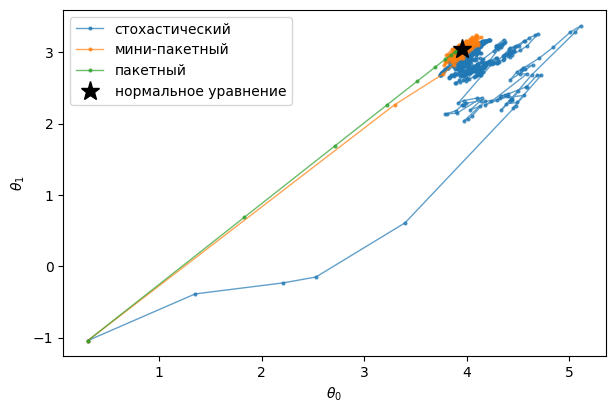

In [60]:
paths = {'стохастический': path_sgd, 'мини-пакетный': path_mini_batch, 'пакетный': path_batch}

for label, path in paths.items():
    plt.plot(path[:, 0], path[:, 1], 'o-', markersize=2, linewidth=1, alpha=0.7, label=label)
plt.plot(*theta_normal, 'k*', markersize=14, label='нормальное уравнение')
plt.xlabel(r'$\theta_0$')
plt.ylabel(r'$\theta_1$')
plt.legend()
plt.show()

Вблизи минимума видно главное: пакетный путь ровный и останавливается в минимуме, стохастический и мини-пакетный продолжают бродить рядом.

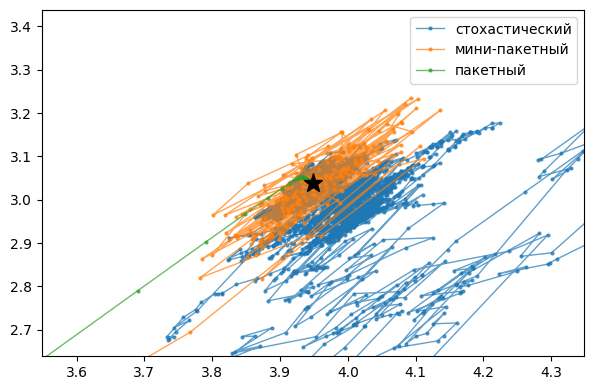

In [61]:
for label, path in paths.items():
    plt.plot(path[:, 0], path[:, 1], 'o-', markersize=2, linewidth=1, alpha=0.7, label=label)
plt.plot(*theta_normal, 'k*', markersize=14)
plt.xlim(theta_normal[0] - 0.4, theta_normal[0] + 0.4)
plt.ylim(theta_normal[1] - 0.4, theta_normal[1] + 0.4)
plt.legend()
plt.show()

## Сравнение алгоритмов

Все способы сошлись к почти одинаковым параметрам и почти одинаковой MSE:

In [62]:
thetas = {
    'нормальное уравнение': theta_normal,
    'пакетный спуск': theta,
    'стохастический спуск': theta_sgd,
    'мини-пакетный спуск': theta_mini_batch,
    'SGDRegressor': np.r_[sgd_reg.intercept_, sgd_reg.coef_],
}
comparison = pd.DataFrame(thetas, index=['theta_0', 'theta_1']).T
comparison['MSE'] = [mse(theta_value, X_b, y) for theta_value in thetas.values()]
comparison.round(4)

,theta_0,theta_1,MSE
нормальное уравнение,3.9487,3.0383,0.9589
пакетный спуск,3.9487,3.0383,0.9589
стохастический спуск,3.9665,3.0457,0.9595
мини-пакетный спуск,4.0138,3.0831,0.9713
SGDRegressor,3.9632,3.0467,0.9594


Чем алгоритмы различаются — таблица 4.1 книги (стр. 171), $m$ — число образцов, $n$ — число признаков:

| Алгоритм | Большое $m$ | Вне памяти | Большое $n$ | Нужно масштабирование | Scikit-Learn |
|---|---|---|---|---|---|
| нормальное уравнение | быстро | нет | медленно | нет | `LinearRegression` |
| пакетный спуск | медленно | нет | быстро | да | — |
| стохастический спуск | быстро | да | быстро | да | `SGDRegressor` |
| мини-пакетный спуск | быстро | да | быстро | да | — |

# Задание: пульс бегуна

Фитнес-браслет записывает тренировки бегуна: средняя скорость, набор высоты на маршруте, температура воздуха и средний пульс. Нужно научиться прогнозировать пульс по трём остальным величинам линейной регрессией — и проверить, что градиентные методы приходят к тому же ответу, что и `LinearRegression`.

Данные сгенерированы функцией ниже и записаны в `data/runs.csv`. Выполните ячейку и работайте с файлом.

In [63]:
from pathlib import Path


def make_heart_rate_csv(path, seed=0):
    """Генерирует журнал пробежек с пульсом и пишет его в CSV.

    Args:
        path: Путь к CSV-файлу.
        seed: Зерно генератора случайных чисел.

    Returns:
        Путь к записанному файлу.
    """
    generator = np.random.default_rng(seed)
    n_runs = 400
    runs = pd.DataFrame({
        'speed_kmh': generator.uniform(8, 14, n_runs),
        'elevation_gain_m': generator.uniform(0, 300, n_runs),
        'temperature_c': generator.uniform(-10, 30, n_runs),
    })
    runs['heart_rate'] = (
        55
        + 7.5 * runs['speed_kmh']
        + 0.08 * runs['elevation_gain_m']
        + 0.4 * runs['temperature_c']
        + generator.normal(0, 5, n_runs)
    )
    path.parent.mkdir(parents=True, exist_ok=True)
    runs.round(2).to_csv(path, index=False)
    return path


runs_path = make_heart_rate_csv(Path('data') / 'runs.csv')
runs_path

PosixPath('data/runs.csv')

### Задание 1

Загрузите `data/runs.csv` в `runs_task`, отделите признаки `X_task` от целевого признака `y_task` (`heart_rate`) и разбейте их `train_test_split(test_size=0.2, random_state=42)` на `X_train_task`, `X_test_task`, `y_train_task`, `y_test_task`. Обучите `LinearRegression` на обучающей части, выведите свободный член и веса признаков и посчитайте RMSE на тестовой. На сколько ударов в минуту поднимает пульс лишний километр в час?

### Задание 2

Стандартизируйте признаки `StandardScaler` (обучите его только на обучающей части) и добавьте столбец единиц. Напишите функцию `batch_gradient_descent(features, target, learning_rate, n_iterations)`, которая выполняет пакетный градиентный спуск с нулевых параметров и возвращает итоговые параметры и список MSE после каждой итерации. Обучите модель с `learning_rate=0.1` и `n_iterations=1000`, посчитайте RMSE на тестовой части и сравните с заданием 1. Почему параметры отличаются от весов `LinearRegression`, а прогнозы совпадают?

### Задание 3

Запустите `batch_gradient_descent` на стандартизованных данных со скоростями обучения 0.01, 0.1 и 1.1 и 100 итерациями. Нарисуйте кривые MSE по итерациям на одном графике в логарифмической шкале. Какая скорость расходится? Какой из двух оставшихся хватает 100 итераций?

### Задание 4

Обучите `SGDRegressor(penalty=None, random_state=42)` дважды: на исходных признаках и в конвейере `make_pipeline(StandardScaler(), SGDRegressor(penalty=None, random_state=42))`. Посчитайте RMSE на тестовой части и сведите в одну таблицу RMSE всех моделей задания: `LinearRegression`, свой пакетный спуск, `SGDRegressor` без масштабирования и с ним. Что случилось со `SGDRegressor` без масштабирования и почему?

# Решение

### Задание 1

In [64]:
from sklearn.model_selection import train_test_split

runs_task = pd.read_csv(Path('data') / 'runs.csv')
X_task = runs_task.drop(columns='heart_rate')
y_task = runs_task['heart_rate']
X_train_task, X_test_task, y_train_task, y_test_task = train_test_split(X_task, y_task, test_size=0.2, random_state=42)
runs_task.head()

,speed_kmh,elevation_gain_m,temperature_c,heart_rate
0,11.82,60.65,24.34,163.66
1,9.62,281.37,14.84,162.07
2,8.25,28.43,-2.24,120.54
3,8.10,1.47,17.52,119.82
4,12.88,96.88,20.36,164.72


In [65]:
from sklearn.metrics import mean_squared_error

lin_reg_task = LinearRegression().fit(X_train_task, y_train_task)
rmse_lin_reg_task = mean_squared_error(y_test_task, lin_reg_task.predict(X_test_task)) ** 0.5
lin_reg_task.intercept_, pd.Series(lin_reg_task.coef_, index=X_task.columns), rmse_lin_reg_task

(53.2431254167316,
 speed_kmh           7.707683
 elevation_gain_m    0.079450
 temperature_c       0.393985
 dtype: float64,
 5.436021099913561)

Лишний километр в час поднимает пульс примерно на 7,5 удара в минуту; RMSE близка к 5 — шуму, заложенному в данные.

### Задание 2

In [66]:
scaler_task = StandardScaler().fit(X_train_task)
X_train_task_b = np.c_[np.ones(len(X_train_task)), scaler_task.transform(X_train_task)]
X_test_task_b = np.c_[np.ones(len(X_test_task)), scaler_task.transform(X_test_task)]
X_train_task_b[:3].round(3)

array([[ 1.   , -1.716, -1.74 ,  0.72 ],
       [ 1.   , -0.768,  0.454, -0.172],
       [ 1.   ,  0.482,  0.612,  0.035]])

In [67]:
def batch_gradient_descent(features, target, learning_rate, n_iterations):
    """Выполняет пакетный градиентный спуск для линейной регрессии.

    Args:
        features: Матрица признаков со столбцом единиц.
        target: Вектор целевых значений.
        learning_rate: Скорость обучения.
        n_iterations: Число итераций.

    Returns:
        Итоговые параметры и список MSE после каждой итерации.
    """
    target = np.asarray(target)
    theta = np.zeros(features.shape[1])
    history = []
    for _ in range(n_iterations):
        gradients = 2 / len(target) * features.T @ (features @ theta - target)
        theta = theta - learning_rate * gradients
        history.append(np.mean((features @ theta - target) ** 2))
    return theta, history

In [68]:
theta_task, history_task = batch_gradient_descent(X_train_task_b, y_train_task, learning_rate=0.1, n_iterations=1000)
rmse_gradient_descent_task = mean_squared_error(y_test_task, X_test_task_b @ theta_task) ** 0.5
theta_task, rmse_gradient_descent_task, rmse_lin_reg_task

(array([155.0719375 ,  13.81471831,   6.80812396,   4.41282422]),
 5.436021099913549,
 5.436021099913561)

In [69]:
np.allclose(X_test_task_b @ theta_task, lin_reg_task.predict(X_test_task))

True

Спуск обучен на стандартизованных признаках: свободный член равен среднему пульсу, а вес — изменение пульса при росте признака на одно стандартное отклонение, а не на единицу. Это та же модель в других координатах, поэтому прогнозы и RMSE совпадают.

### Задание 3

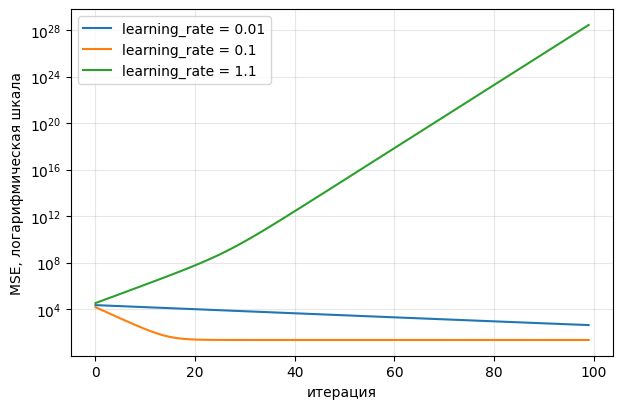

In [70]:
with np.errstate(over='ignore', invalid='ignore'):
    for rate in (0.01, 0.1, 1.1):
        _, history_rate = batch_gradient_descent(X_train_task_b, y_train_task, learning_rate=rate, n_iterations=100)
        plt.semilogy(history_rate, label=f'learning_rate = {rate}')
plt.xlabel('итерация')
plt.ylabel('MSE, логарифмическая шкала')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Скорость 1.1 расходится: MSE растёт с каждой итерацией. Скорость 0.1 выходит на минимум (MSE около 30 — квадрат шума, заложенного в данные) за пару десятков итераций, скорости 0.01 100 итераций не хватает.

### Задание 4

In [71]:
from sklearn.pipeline import make_pipeline

sgd_raw_task = SGDRegressor(penalty=None, random_state=42).fit(X_train_task, y_train_task)
sgd_scaled_task = make_pipeline(StandardScaler(), SGDRegressor(penalty=None, random_state=42))
sgd_scaled_task.fit(X_train_task, y_train_task)
sgd_raw_task.coef_, sgd_scaled_task[-1].coef_

(array([7.01737884e+10, 9.34994314e+10, 3.39363762e+10]),
 array([13.81046859,  6.80055284,  4.40645669]))

In [72]:
rmse_task = pd.Series({
    'LinearRegression': rmse_lin_reg_task,
    'свой пакетный спуск': rmse_gradient_descent_task,
    'SGDRegressor без масштабирования': mean_squared_error(y_test_task, sgd_raw_task.predict(X_test_task)) ** 0.5,
    'SGDRegressor со StandardScaler': mean_squared_error(y_test_task, sgd_scaled_task.predict(X_test_task)) ** 0.5,
}, name='RMSE')
rmse_task.to_frame()

,RMSE
LinearRegression,5.436021e+00
свой пакетный спуск,5.436021e+00
SGDRegressor без масштабирования,1.714493e+13
SGDRegressor со StandardScaler,5.433448e+00


Без масштабирования набор высоты (сотни метров) в десятки раз крупнее скорости (около 10 км/ч): скорость обучения по умолчанию слишком велика для «крупного» признака, спуск скачет или расходится, и RMSE в разы хуже. В конвейере со `StandardScaler` `SGDRegressor` догоняет `LinearRegression`.